## Cargar los datos

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

raiz = Path.cwd()
if not (raiz / "src").exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.dataset import CorrosionDataset, PARTICIONES

datos = {particion: CorrosionDataset(particion).datos for particion in PARTICIONES}
print({particion: len(split) for particion, split in datos.items()})

{'train': 820, 'validation': 125, 'test': 304}


/home/lucas/IA/Vision/deteccion-corrosion/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ejemplo = datos["train"][0]

print(ejemplo.keys())
print(ejemplo["objects"])

dict_keys(['image_id', 'image', 'width', 'height', 'objects'])
{'id': [724, 725], 'area': [391, 251], 'bbox': [[80.0, 289.0, 9.0, 43.5], [109.0, 296.0, 7.5, 33.5]], 'category': [3, 3]}


## Visualizar una imagen con sus cajas

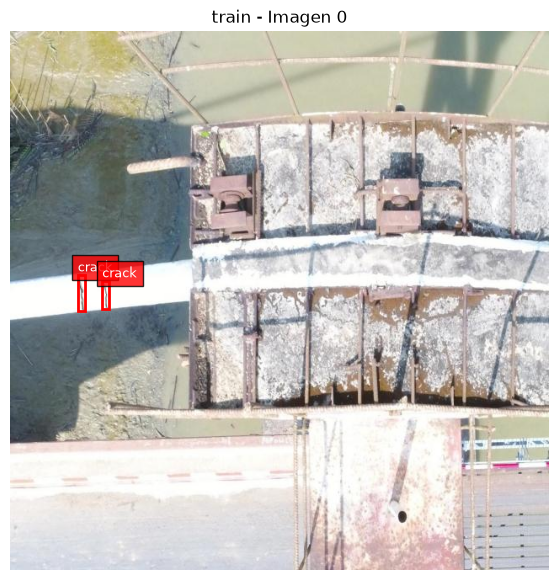

In [3]:
# Nombres de las clases
nombres = datos["train"].features["objects"]["category"].feature.names
def mostrar_imagen(particion="train", indice=0):
    ejemplo = datos[particion][indice]
    imagen = ejemplo["image"]

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(imagen)

    cajas = ejemplo["objects"]["bbox"]
    clases = ejemplo["objects"]["category"]

    for caja, clase in zip(cajas, clases):
        x, y, ancho, alto = caja

        rectangulo = Rectangle(
            (x, y), ancho, alto,
            fill=False,
            edgecolor="red",
            linewidth=2
        )

        ax.add_patch(rectangulo)
        ax.text(
            x, max(0, y - 4),
            nombres[clase],
            color="white",
            fontsize=9,
            bbox={"facecolor": "red", "alpha": 0.8}
        )

    ax.set_title(f"{particion} - Imagen {indice}")
    ax.axis("off")
    plt.show()

mostrar_imagen("train", 0)

## Contar los objetos de cada clase

In [4]:
from collections import Counter

for particion in datos:
    contador = Counter()

    for objetos in datos[particion]["objects"]:
        contador.update(objetos["category"])

    print(f"\n{particion.upper()}")
    for clase, cantidad in sorted(contador.items()):
        print(f"{nombres[clase]}: {cantidad}")


TRAIN
Slippage: 499
corrosion: 1175
crack: 1388

VALIDATION
Slippage: 49
corrosion: 165
crack: 258

TEST
Slippage: 98
corrosion: 317
crack: 867


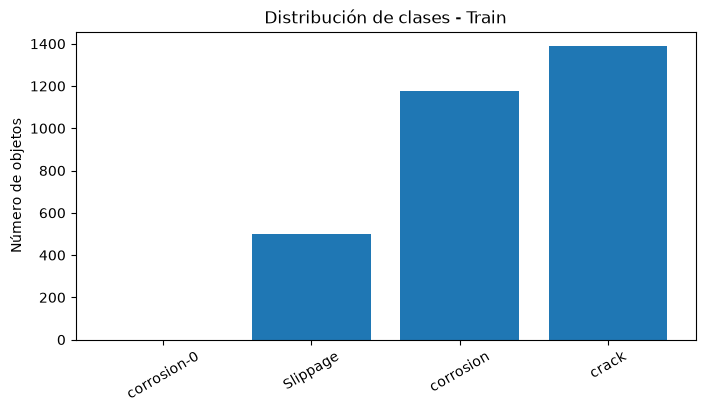

In [5]:
contador = Counter()

for objetos in datos["train"]["objects"]:
    contador.update(objetos["category"])

plt.figure(figsize=(8, 4))
plt.bar(
    nombres,
    [contador.get(i, 0) for i in range(len(nombres))]
)
plt.ylabel("Número de objetos")
plt.title("Distribución de clases - Train")
plt.xticks(rotation=30)
plt.show()

## Analizar los tamaños de los objetos

Objetos totales: 3062
Objetos medios por imagen: 3.73
Máximo de objetos en una imagen: 17
Área mediana: 231.0 píxeles²


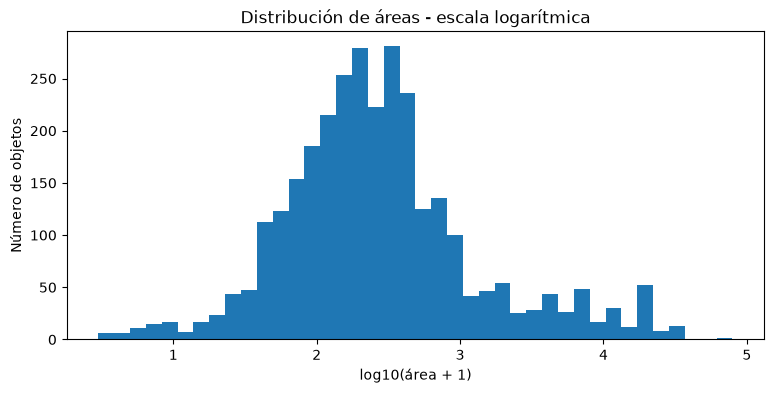

Percentiles de área:
P10: 48.8 px²
P25: 104.1 px²
P50: 231.0 px²
P75: 519.6 px²
P90: 2158.4 px²
P95: 6708.2 px²
P99: 20084.2 px²
Pequeños: 85.2%
Medianos: 10.6%
Grandes: 4.2%
Objetos pequeños (área < 32²): 85.2%


In [6]:
import numpy as np

areas = []
objetos_por_imagen = []

for objetos in datos["train"]["objects"]:
    cajas = objetos["bbox"]
    objetos_por_imagen.append(len(cajas))

    for x, y, ancho, alto in cajas:
        areas.append(ancho * alto)

areas = np.array(areas)

print(f"Objetos totales: {len(areas)}")
print(f"Objetos medios por imagen: {np.mean(objetos_por_imagen):.2f}")
print(f"Máximo de objetos en una imagen: {max(objetos_por_imagen)}")
print(f"Área mediana: {np.median(areas):.1f} píxeles²")

plt.figure(figsize=(9, 4))

plt.hist(np.log10(areas + 1), bins=40)

plt.xlabel("log10(área + 1)")
plt.ylabel("Número de objetos")
plt.title("Distribución de áreas - escala logarítmica")
plt.show()

print("Percentiles de área:")
for p in [10, 25, 50, 75, 90, 95, 99]:
    print(f"P{p}: {np.percentile(areas, p):.1f} px²")

pequenos = np.sum(areas < 32**2)
medianos = np.sum((areas >= 32**2) & (areas < 96**2))
grandes = np.sum(areas >= 96**2)

for nombre, cantidad in [
    ("Pequeños", pequenos),
    ("Medianos", medianos),
    ("Grandes", grandes),
]:
    print(f"{nombre}: {cantidad / len(areas) * 100:.1f}%")

# Criterio de tamaño pequeño usado por COCO
porcentaje = np.mean(areas < 32**2) * 100
print(f"Objetos pequeños (área < 32²): {porcentaje:.1f}%")

In [7]:
print(f"Área mínima: {areas.min():.2f} px²")
print(f"Área mediana: {np.median(areas):.2f} px²")
print(f"Área máxima: {areas.max():.2f} px²")

print(f"\nObjetos < 16 px²: {np.mean(areas < 16) * 100:.2f}%")
print(f"Objetos < 100 px²: {np.mean(areas < 100) * 100:.2f}%")
print(f"Objetos < 1024 px²: {np.mean(areas < 1024) * 100:.2f}%")


Área mínima: 2.00 px²
Área mediana: 231.00 px²
Área máxima: 79265.00 px²

Objetos < 16 px²: 2.32%
Objetos < 100 px²: 23.97%
Objetos < 1024 px²: 85.17%


## Conclusiones

El dataset Corrosion-bi3q3 contiene 1.249 imágenes distribuidas en entrenamiento (820), validación (125) y test (304). Aunque se definen cuatro etiquetas, únicamente aparecen anotaciones de tres clases: Slippage, corrosion y crack. La clase corrosion-0 no tiene anotaciones en ninguna partición.

Se observa un desequilibrio en la distribución de clases. En entrenamiento hay 1.388 anotaciones de crack, 1.175 de corrosion y 499 de Slippage. Por indicación del profesor, ambos modelos usan el reparto corregido que traslada 20 imágenes completas de train a validación. Validación contiene ahora 49 anotaciones de Slippage, 165 de corrosion y 258 de crack.

El principal desafío del dataset es el reducido tamaño de los objetos. El 85,17 % de las cajas tienen un área inferior a 1.024 px², con una mediana de 231 px². Algunas anotaciones llegan a tener áreas de tan solo 2 px². Esto puede dificultar considerablemente la detección y localización precisa de los defectos.

La inspección visual también ha permitido identificar posibles inconsistencias en las anotaciones, como zonas aparentemente oxidadas que no están etiquetadas. Sería conveniente revisar más ejemplos para determinar si se trata de anotaciones incompletas o de criterios específicos del dataset.

En consecuencia, los experimentos con Faster R-CNN v2 y RetinaNet v2 deberían prestar especial atención a la detección de objetos pequeños. Se plantean como posibles estrategias de mejora el ajuste de la resolución de entrada y la adaptación de los anchors a los tamaños y proporciones de las cajas. También será importante analizar el rendimiento por clase y considerar el desequilibrio de clases al interpretar los resultados.